In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams


In [2]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)
plt.rcParams.update({
    "font.family": "Libertinus Serif",
    "font.size": CORPS,
    "axes.labelsize": CORPS,
    "legend.fontsize": CORPS,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
FIG_DIR  = Path("../../fig/H7")
FIG_DIR.mkdir(exist_ok=True)

db = pd.read_excel("../../data/algemeen/gebeurtenisdata_meso/steekproefdatabank_gis.xlsx")

db["uur"] = pd.to_datetime(db["hour_processed"], errors="coerce").dt.hour

print(f"{len(db):,} rijen geladen")

5,847 rijen geladen


/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_44718/2241358839.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  db["uur"] = pd.to_datetime(db["hour_processed"], errors="coerce").dt.hour


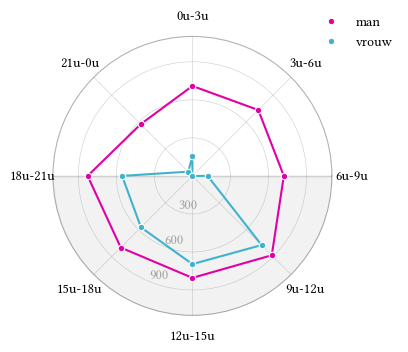

            med             n       
gender      man  woman    man  woman
tijdslot                            
6u-9u     721.0  120.0  112.0   61.0
9u-12u    885.0  772.0  281.0  171.0
12u-15u   804.0  696.0  277.0  106.0
15u-18u   799.0  574.0  278.0   85.0
18u-21u   827.0  555.0  290.0   71.0
21u-0u    577.0   47.0  170.0   73.0
0u-3u     709.0  153.0  211.0  137.0
3u-6u     735.0    0.0   81.0   22.0


In [4]:
TIJD_VOLGORDE = ["6u-9u", "9u-12u", "12u-15u", "15u-18u",
                 "18u-21u", "21u-0u", "0u-3u", "3u-6u"]
KLEUR = {"man": KLEUR_MAN, "woman": KLEUR_VROUW}

# --- data: mediaan per gender en tijdslot (nulwaarden meegenomen) ----------
d_st = db[db["gender"].isin(["man", "woman"])].dropna(subset=["dis_loc_res"]).copy()
d_st["tijdslot"] = pd.cut(d_st["uur"], bins=[0, 3, 6, 9, 12, 15, 18, 21, 24],
                          labels=["0u-3u", "3u-6u", "6u-9u", "9u-12u",
                                  "12u-15u", "15u-18u", "18u-21u", "21u-0u"],
                          right=False)
d_st = d_st.dropna(subset=["tijdslot", "uur"])
d_st["tijdslot"] = d_st["tijdslot"].astype(str)

stat = (d_st.groupby(["gender", "tijdslot"])["dis_loc_res"]
        .agg(med="median", n="size").reset_index())

# --- hoeken ----------------------------------------------------------------
hoeken = np.linspace(0, 2 * np.pi, len(TIJD_VOLGORDE), endpoint=False)
dicht = lambda a: np.append(a, a[0])
hoeken_d = dicht(hoeken)

fig_st, ax_st = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.8),
                             subplot_kw={"projection": "polar"})
fig_st.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.08)

# oriëntatie: 0u-3u (index 6) bovenaan, met de klok mee
ax_st.set_theta_zero_location("N")
ax_st.set_theta_direction(-1)
ax_st.set_theta_offset(np.pi / 2 + 6 * (2 * np.pi / 8))

# grijze nachtsector (18u–6u)
theta_grijs = np.linspace(0, np.pi, 200)
ax_st.fill_between(theta_grijs, 0, 1100, color="grey", alpha=0.10, zorder=0)

# --- sterren ---------------------------------------------------------------
for g_st in ["man", "woman"]:
    sub = stat[stat["gender"] == g_st].set_index("tijdslot").reindex(TIJD_VOLGORDE)
    ax_st.plot(hoeken_d, dicht(sub["med"].values), color=KLEUR[g_st], lw=1.5, zorder=3)
    ax_st.scatter(hoeken, sub["med"].values, s=22, color=KLEUR[g_st],
                  edgecolor="white", linewidth=0.8, zorder=4,
                  label="man" if g_st == "man" else "vrouw")

# --- opmaak ----------------------------------------------------------------
ax_st.set_xticks(hoeken)
ax_st.set_xticklabels(TIJD_VOLGORDE, fontsize=CORPS)
ax_st.set_ylim(0, 1100)
ax_st.set_rlabel_position(112)
ax_st.set_rgrids([300, 600, 900], fontsize=CORPS, color="grey", alpha=0.7)
ax_st.tick_params(axis="x", pad=4)
ax_st.grid(True)
ax_st.spines["polar"].set_alpha(0.3)
fig_st.legend(frameon=False, loc="upper right", bbox_to_anchor=(1.0, 1.0))

pas_breedte_aan(fig_st)
fig_st.savefig(FIG_DIR / "7.3_afstand_ster_mediaan.png", dpi=300)
plt.show()

# cijfers voor bijschrift
print(stat.pivot(index="tijdslot", columns="gender",
                 values=["med", "n"]).reindex(TIJD_VOLGORDE).round(0))

In [5]:
# N per gender en mediaan + aandeel op 0 meter per tijdslot (nulwaarden meegenomen)
d_n = db[db["gender"].isin(["man", "woman"])].dropna(subset=["dis_loc_res", "uur"]).copy()

print("Totaal met gender + afstand + uur:", len(d_n))
print("Waarvan op 0 meter:", int((d_n["dis_loc_res"] == 0).sum()))
print("\nN per gender (inclusief 0 meter):")
print(d_n.groupby("gender").size())

d_n["tijdslot"] = pd.cut(d_n["uur"], bins=[0, 3, 6, 9, 12, 15, 18, 21, 24],
                         labels=["0u-3u", "3u-6u", "6u-9u", "9u-12u",
                                 "12u-15u", "15u-18u", "18u-21u", "21u-0u"],
                         right=False)
stat_n = (d_n.dropna(subset=["tijdslot"])
          .groupby(["gender", "tijdslot"], observed=True)["dis_loc_res"]
          .agg(med="median",
               aandeel_nul=lambda s: (s == 0).mean(),
               n="size").reset_index())

print("\nMediaan (incl. 0), aandeel op 0 meter, en n per tijdslot:")
print(stat_n.pivot(index="tijdslot", columns="gender",
                   values=["med", "aandeel_nul", "n"])
      .reindex(TIJD_VOLGORDE).round(2))

Totaal met gender + afstand + uur: 2426
Waarvan op 0 meter: 390

N per gender (inclusief 0 meter):
gender
man      1700
woman     726
dtype: int64

Mediaan (incl. 0), aandeel op 0 meter, en n per tijdslot:
             med        aandeel_nul            n       
gender       man  woman         man woman    man  woman
tijdslot                                               
6u-9u     720.95  119.8        0.19  0.41  112.0   61.0
9u-12u    885.30  771.6        0.08  0.13  281.0  171.0
12u-15u   804.20  695.9        0.08  0.11  277.0  106.0
15u-18u   799.40  573.9        0.08  0.19  278.0   85.0
18u-21u   826.65  554.8        0.11  0.27  290.0   71.0
21u-0u    576.90   47.1        0.14  0.49  170.0   73.0
0u-3u     709.20  153.1        0.19  0.36  211.0  137.0
3u-6u     735.00    0.0        0.17  0.55   81.0   22.0


woman: n=47, 0m=9%, Q1=213, med=651, Q3=1246
man: n=134, 0m=10%, Q1=224, med=934, Q3=1736


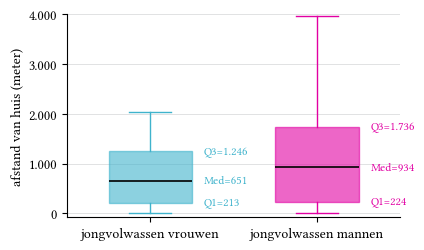

In [6]:
SCHEMER = ["nacht", "ochtendschemer", "avondschemer"]
KLEUR = {"man": KLEUR_MAN, "woman": KLEUR_VROUW}

d_bx = db[db["gender"].isin(["man", "woman"])
          & db["age"].between(15, 24)
          & db["E_TIME_astro"].isin(SCHEMER)].dropna(subset=["dis_loc_res"]).copy()

data = {g: d_bx[d_bx["gender"] == g]["dis_loc_res"].values for g in ["woman", "man"]}

# controlegetallen
for g in ["woman", "man"]:
    v = data[g]
    print(f"{g}: n={len(v)}, 0m={np.mean(v == 0):.0%}, "
          f"Q1={np.percentile(v, 25):.0f}, med={np.median(v):.0f}, "
          f"Q3={np.percentile(v, 75):.0f}")

fig_bx, ax_bx = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.62))
bp = ax_bx.boxplot([data["woman"], data["man"]], widths=0.5,
                   patch_artist=True, showfliers=False,
                   medianprops=dict(color="black", lw=1.2),
                   tick_labels=["jongvolwassen vrouwen", "jongvolwassen mannen"])

for patch, g in zip(bp["boxes"], ["woman", "man"]):
    patch.set_facecolor(KLEUR[g]); patch.set_alpha(0.6); patch.set_edgecolor(KLEUR[g])
for elem in ("whiskers", "caps"):
    for line, g in zip(bp[elem], ["woman", "woman", "man", "man"]):
        line.set_color(KLEUR[g])

# kwartielannotaties (met punt voor de duizendtallen)
nl_dzd = lambda v: f"{v:,.0f}".replace(",", ".")
for i, g in enumerate(["woman", "man"]):
    v = data[g]
    q1, med, q3 = np.percentile(v, [25, 50, 75])
    for waarde, lab in [(q1, f"Q1={nl_dzd(q1)}"), (med, f"Med={nl_dzd(med)}"), (q3, f"Q3={nl_dzd(q3)}")]:
        ax_bx.annotate(lab, xy=(i + 1, waarde), xytext=(i + 1 + 0.32, waarde),
                       fontsize=CORPS_KLEIN, color=KLEUR[g], va="center", ha="left")

ax_bx.set_ylabel("afstand van huis (meter)")
ax_bx.set_ylim(-80, 4000)
from matplotlib.ticker import FuncFormatter
ax_bx.yaxis.set_major_formatter(FuncFormatter(lambda v, _: nl_dzd(v)))
ax_bx.yaxis.grid(True)
for r in ("top", "right"):
    ax_bx.spines[r].set_visible(False)

pas_breedte_aan(fig_bx, tight=True)
fig_bx.savefig(FIG_DIR / "7.4_boxplot_jongvolwassenen.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
SCHEMER = ["nacht", "ochtendschemer", "avondschemer"]

print(
    db[db["gender"].eq("woman") & db["E_TIME_astro"].isin(SCHEMER)]
      .assign(leeftijd=lambda d: pd.cut(d["age"], [0, 14, 24, 64, 120],
              labels=["kind", "jongvolw.", "volw.", "ouder"]))
      .groupby("leeftijd", observed=True)["dis_loc_res"].agg(["median", "size"])
      .round(0)
)

           median  size
leeftijd               
kind        384.0    15
jongvolw.   651.0    92
volw.        67.0   284
ouder         0.0     8


In [8]:
SCHEMER = ["nacht", "ochtendschemer", "avondschemer"]

BEROEPSGROEPEN = {
    "sekswerker":     ["Prostitute"],
    "straatverkoper": ["Street Vendor"], 
}

d = db[db["gender"] == "woman"].dropna(subset=["dis_loc_res", "prof_hisco"]).copy()
d["periode"] = d["E_TIME_astro"].apply(
    lambda x: "dag" if x == "dag" else ("nacht" if x in SCHEMER else None))

rijen = []
for naam, labels in BEROEPSGROEPEN.items():
    for leeftijd, masker in [("alle", d["age"].notna() | d["age"].isna()),
                             ("15-24", d["age"].between(15, 24))]:
        for periode in ["dag", "nacht"]:
            v = d.loc[d["prof_hisco"].isin(labels) & masker
                      & (d["periode"] == periode), "dis_loc_res"]
            if len(v):
                rijen.append({
                    "beroep": naam, "leeftijd": leeftijd, "periode": periode,
                    "n": len(v),
                    "mediaan_m": round(v.median()),
                    "Q1": round(v.quantile(.25)), "Q3": round(v.quantile(.75)),
                    "0m": f"{(v == 0).mean():.0%}",
                })

print(pd.DataFrame(rijen).to_string(index=False))

        beroep leeftijd periode   n  mediaan_m  Q1   Q3   0m
    sekswerker     alle     dag  11          0   0   26  73%
    sekswerker     alle   nacht  94        114   0  609  43%
    sekswerker    15-24     dag   3          0   0    0 100%
    sekswerker    15-24   nacht   7        153  24  524  29%
straatverkoper     alle     dag 145        816 420 1136   5%
straatverkoper     alle   nacht  24        621 414 1149   8%
straatverkoper    15-24     dag  45        754 622  950   2%
straatverkoper    15-24   nacht   8        773 414 1209   0%
